# Normalizing flows: learning flexible probability distributions

A normalizing flow learns an invertible transformation between a simple base random variable and a complex observation:

\[
z\sim p_Z(z),\qquad x=T_\theta(z).
\]

Because \(T_\theta\) is invertible, the density of an observed \(x\) is available through change of variables:

\[
\log p_X(x)
=\log p_Z(T_\theta^{-1}(x))
+\log\left|\det J_{T_\theta^{-1}}(x)\right|.
\]

This is the property we need: **flexible distributions while retaining likelihood-based training and sampling**.

In [1]:
from pathlib import Path
import sys, numpy as np, pandas as pd, matplotlib.pyplot as plt
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})
from lifetime_clinical.tutorials.textbook import scaled_sinh_arcsinh_forward, scaled_sinh_arcsinh_inverse

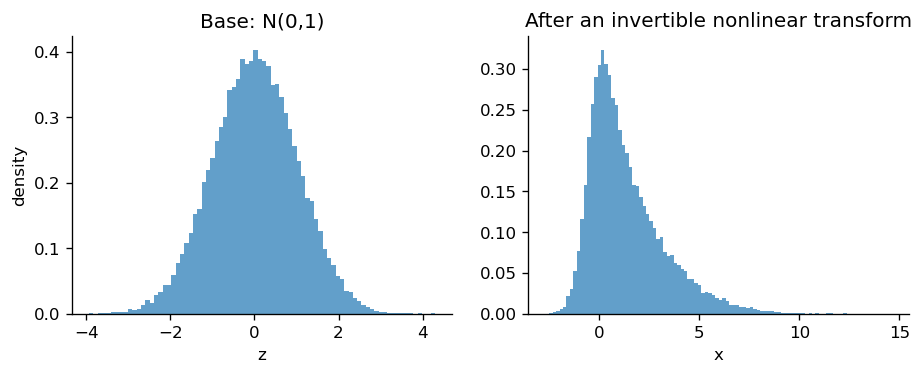

In [2]:
rng=np.random.default_rng(12); z=rng.normal(size=30000); x=scaled_sinh_arcsinh_forward(z,skew=.65,tail=1.2)
fig,axes=plt.subplots(1,2,figsize=(9,3))
axes[0].hist(z,bins=80,density=True,alpha=.7); axes[0].set(title="Base: N(0,1)",xlabel="z",ylabel="density")
axes[1].hist(x,bins=100,density=True,alpha=.7); axes[1].set(title="After an invertible nonlinear transform",xlabel="x")
plt.show()

## What makes a neural transformation invertible?

An ordinary neural network is not automatically invertible. The transformation must be **bijective** on its stated domain and codomain: distinct inputs must produce distinct outputs, and every output must have exactly one input. A standard flow preserves dimension. Reducing dimension or using a many-to-one operation such as ReLU on an unrestricted real input loses information and prevents exact inversion.

For the smooth, likelihood-based flows discussed here, we also want:

- **A well-defined inverse** that we can evaluate efficiently for density estimation.
- **A nonsingular Jacobian**, so the change-of-variables formula is valid. A nonzero determinant alone gives local invertibility; it does not establish a global bijection.
- **A tractable log absolute Jacobian determinant**, so likelihood computation and training remain practical.

One construction is to compose invertible layers: reverse their order and invert each layer to recover the input. Ordinary dense layers would need square, full-rank weight matrices and invertible activations to use this approach. Special flow architectures can instead guarantee invertibility structurally. Neural networks that only predict a flow's parameters from a fixed context do **not** themselves need to be invertible; the transformation of the random variable does.

### Why the sinh–arcsinh example qualifies

The notebook's example uses a scalar analytic transformation rather than a trained neural network:

\[
T(z)=\sinh\left(b[\operatorname{arcsinh}(z)+a]\right),
\qquad a=\texttt{skew},\quad b=\texttt{tail}>0.
\]

Both \(\sinh\) and \(\operatorname{arcsinh}\) are bijections from \(\mathbb R\) to \(\mathbb R\), and they are inverses of each other. Adding \(a\) and multiplying by a nonzero \(b\) are also invertible. Their composition therefore has the explicit inverse

\[
T^{-1}(x)=\sinh\left(\frac{\operatorname{arcsinh}(x)}{b}-a\right).
\]

For \(b>0\), its derivative is strictly positive everywhere:

\[
T'(z)=\frac{b\cosh\left(b[\operatorname{arcsinh}(z)+a]\right)}{\sqrt{1+z^2}}>0.
\]

Thus it is monotone, its Jacobian never vanishes, and the log determinant is analytic. In one dimension the determinant is just the derivative, and \(\log |(T^{-1})'(x)|=-\log |T'(z)|\) at \(z=T^{-1}(x)\). This supplies the correction required for an exact density. The histogram example only illustrates sampling; it does not train parameters or calculate that likelihood correction.

Here is the implementation from `lifetime_clinical/tutorials/textbook.py`:

```python
def scaled_sinh_arcsinh_forward(z, skew=.7, tail=1.25):
    z=np.asarray(z,float)
    return np.sinh(tail*(np.arcsinh(z)+skew))

def scaled_sinh_arcsinh_inverse(y, skew=.7, tail=1.25):
    y=np.asarray(y,float)
    return np.sinh(np.arcsinh(y)/tail-skew)
```

The forward function applies arcsinh, shift, scale and sinh. The inverse undoes those operations in reverse order: arcsinh, divide by `tail`, subtract `skew`, then sinh. The notebook uses `tail=1.2`, which satisfies the positive-tail condition. These helper functions do not validate `tail`; callers must keep it nonzero (positive for the increasing transformation described here). A learned positive tail could be parameterised as `exp(raw_tail)` rather than learned without constraints. The numerical inversion is subject to floating-point range and precision, as with other implementations.


### Visualising the functions and their composition

First, compare \(\sinh(u)\) and \(\operatorname{arcsinh}(u)\). Both are strictly increasing and undo each other: sinh expands large magnitudes, while arcsinh compresses them.

The next figure follows the implementation with the same `skew=0.65` and `tail=1.2` used in the histogram example. Each of the first four panels plots an **intermediate result against the original input \(z\)**, so you can follow how the whole curve changes:

\[
z\ \longrightarrow\ u=\operatorname{arcsinh}(z)
\ \longrightarrow\ v=u+\texttt{skew}
\ \longrightarrow\ w=\texttt{tail}\,v
\ \longrightarrow\ x=\sinh(w)=T(z).
\]

Coloured dots track the same three inputs through every stage. Panel five shows the explicit inverse, with the tracked outputs mapped back to their original inputs. Panel six checks that \(T^{-1}(T(z))=z\). These are deterministic function plots; the earlier histograms show how applying the overall transformation changes a probability distribution.


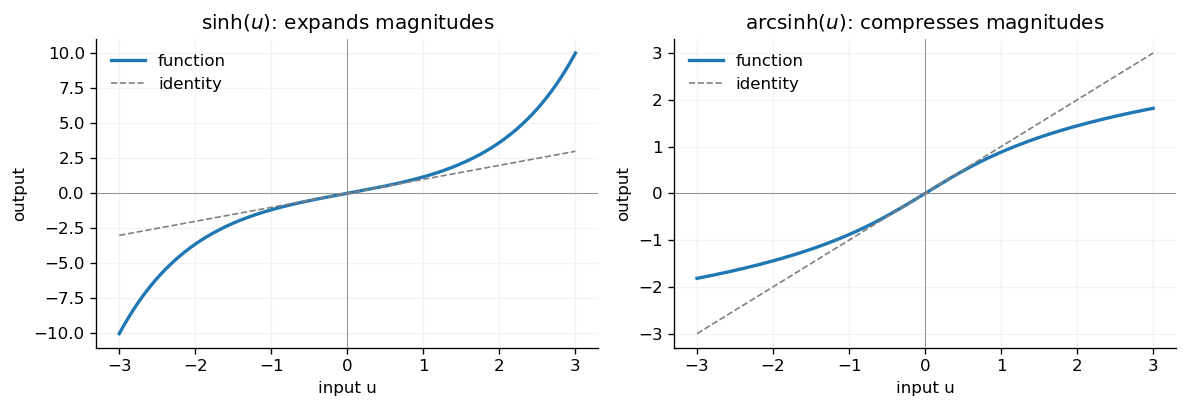

In [3]:
u = np.linspace(-3, 3, 601)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, values, title in [
    (axes[0], np.sinh(u), r"$\sinh(u)$: expands magnitudes"),
    (axes[1], np.arcsinh(u), r"$\operatorname{arcsinh}(u)$: compresses magnitudes"),
]:
    ax.plot(u, values, linewidth=2, label="function")
    ax.plot(u, u, "--", color="grey", linewidth=1, label="identity")
    ax.axhline(0, color="grey", linewidth=.5)
    ax.axvline(0, color="grey", linewidth=.5)
    ax.set(title=title, xlabel="input u", ylabel="output")
    ax.legend(frameon=False)
    ax.grid(alpha=.15)
fig.tight_layout()
plt.show()


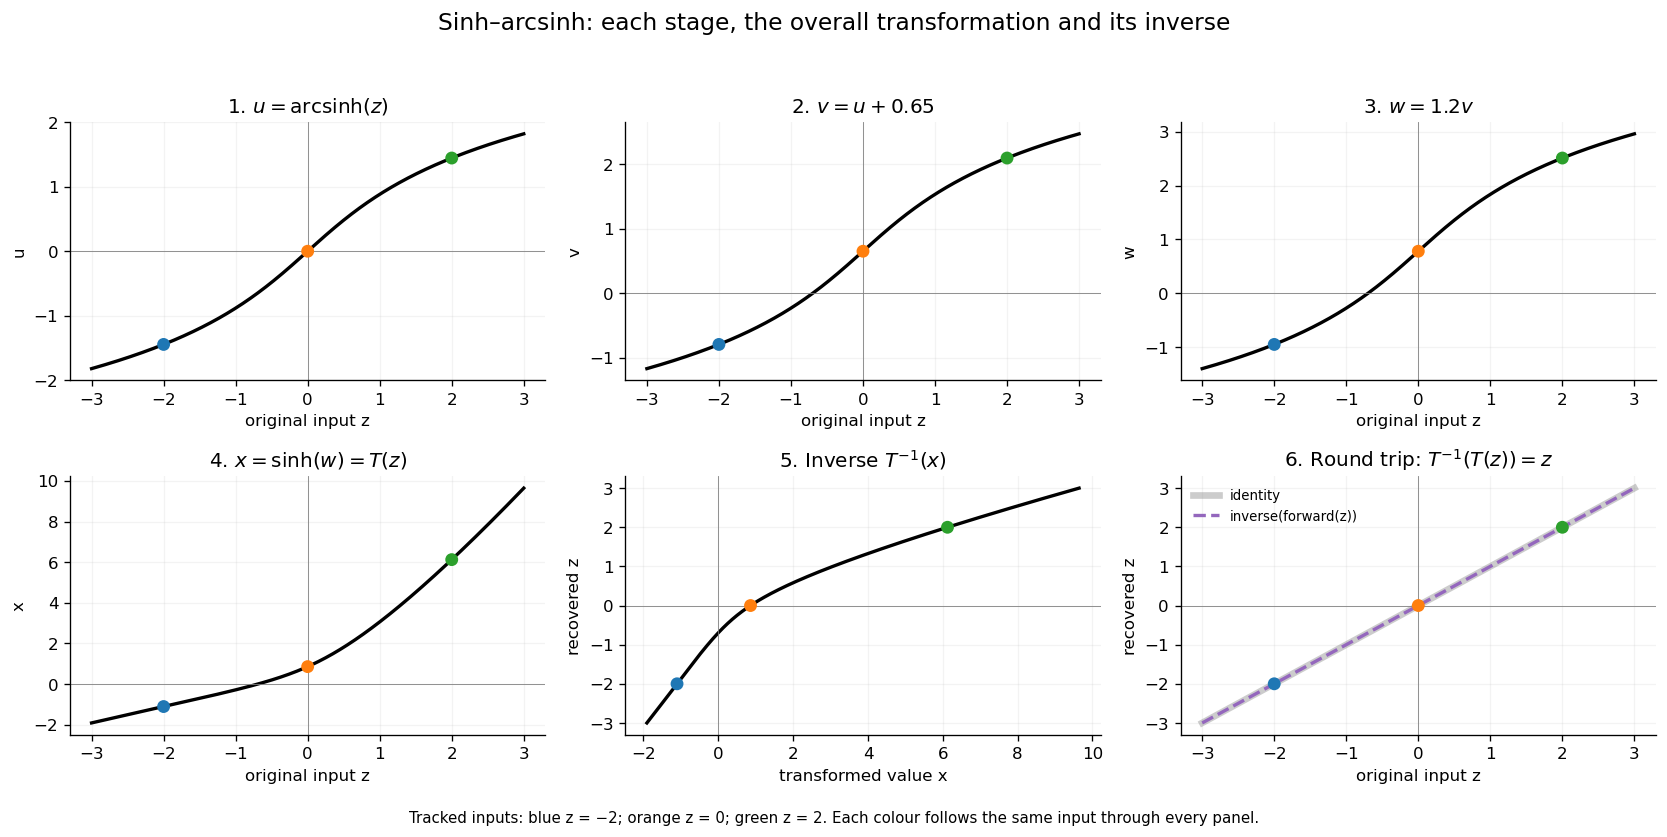

Maximum forward/inverse round-trip error: 1.78e-15


In [4]:
skew, tail = .65, 1.2
z_grid = np.linspace(-3, 3, 601)
u_grid = np.arcsinh(z_grid)
v_grid = u_grid + skew
w_grid = tail * v_grid
x_grid = scaled_sinh_arcsinh_forward(z_grid, skew=skew, tail=tail)
tracked_z = np.array([-2., 0., 2.])
tracked_x = scaled_sinh_arcsinh_forward(tracked_z, skew=skew, tail=tail)
tracked_colours = ["tab:blue", "tab:orange", "tab:green"]
tracked_stages = [np.arcsinh(tracked_z), np.arcsinh(tracked_z)+skew,
                  tail*(np.arcsinh(tracked_z)+skew), tracked_x]

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
stages = [
    (u_grid, r"1. $u=\operatorname{arcsinh}(z)$", "u"),
    (v_grid, r"2. $v=u+0.65$", "v"),
    (w_grid, r"3. $w=1.2v$", "w"),
    (x_grid, r"4. $x=\sinh(w)=T(z)$", "x"),
]
for ax, (values, title, ylabel), tracked_values in zip(axes.flat, stages, tracked_stages):
    ax.plot(z_grid, values, color="black", linewidth=2)
    ax.scatter(tracked_z, tracked_values, c=tracked_colours, s=45, zorder=3)
    ax.set(title=title, xlabel="original input z", ylabel=ylabel)

inverse_grid = scaled_sinh_arcsinh_inverse(x_grid, skew=skew, tail=tail)
axes[1, 1].plot(x_grid, inverse_grid, color="black", linewidth=2)
axes[1, 1].scatter(tracked_x, tracked_z, c=tracked_colours, s=45, zorder=3)
axes[1, 1].set(title=r"5. Inverse $T^{-1}(x)$", xlabel="transformed value x", ylabel="recovered z")
axes[1, 2].plot(z_grid, z_grid, color="grey", linewidth=4, alpha=.4, label="identity")
axes[1, 2].plot(z_grid, inverse_grid, "--", color="tab:purple", linewidth=2, label="inverse(forward(z))")
axes[1, 2].scatter(tracked_z, tracked_z, c=tracked_colours, s=45, zorder=3)
axes[1, 2].set(title=r"6. Round trip: $T^{-1}(T(z))=z$", xlabel="original input z", ylabel="recovered z")
axes[1, 2].legend(frameon=False, fontsize=8)
for ax in axes.flat:
    ax.axhline(0, color="grey", linewidth=.5)
    ax.axvline(0, color="grey", linewidth=.5)
    ax.grid(alpha=.15)
fig.suptitle("Sinh–arcsinh: each stage, the overall transformation and its inverse", fontsize=14)
fig.tight_layout(rect=(0, .04, 1, .95))
fig.text(.5, .015, "Tracked inputs: blue z = −2; orange z = 0; green z = 2. Each colour follows the same input through every panel.", ha="center", fontsize=9)
plt.show()
max_round_trip_error = np.max(np.abs(inverse_grid - z_grid))
print(f"Maximum forward/inverse round-trip error: {max_round_trip_error:.2e}")
np.testing.assert_allclose(inverse_grid, z_grid, atol=1e-12)


## Conditional flows

The transformation may depend on a deterministic context \(H\):

\[
x=T_\theta(z;H).
\]

For the same base \(z\sim\mathcal N(0,1)\), different patient histories can therefore induce very different predictive distributions.

This is exactly what we need for event times:

\[
\tau_{next}=T_\tau(z;H_t),
\]

or equivalently during fitting

\[
z=T_\tau^{-1}(\tau_{next};H_t).
\]

The flow learns the *shape* of \(p(\tau_{next}\mid H_t)\), not merely its mean.

## Where flows enter this repository

1. **TPP timing:** learn a flexible positive distribution for the next IAT.
2. **Dynamic feature state:** map continuous physiology snapshots to/from a simple latent distribution.
3. **Transformed GP observations:** \(y=T(f+\epsilon_G)\) permits non-Gaussian observed marginals while retaining an exact change-of-variable likelihood.
4. **Residual GP:** \(y=f+T(z)\) gives an explicit non-Gaussian residual, at the cost of approximate GP marginal inference.

Flows do **not** replace the causal history encoder or the GP. They solve a different problem: flexible density geometry.

## Constraints worth remembering

- A standard flow is dimension preserving and invertible; it is not a dimensionality-reduction method.
- Layer normalization does not imply \(z\sim\mathcal N(0,I)\); matching moments is not the same as matching a joint distribution.
- An expressive flow can make a distribution skewed, heavy-tailed or multimodal, but a specific flow family may be much more restricted.
- In a conditional flow, the context \(H_t\) is deterministic for a fixed observed history; randomness comes from the base draw \(z\).